# Bamboo Weekly #189: AI security incidents

The big news over the last few weeks has been full of reports about AI security. This includes
the unsafe, unsavory, and illegal things that people are doing with the help of AI. But it also includes the increasing (and alarming) reports of AI agents performing tasks on their own, including breaking into systems.

People are noticing: A recent issue of Casey Newton's Platformer newsletter talked about how we're starting to hear more people worried about AI, and where this industry is headed: https://www.platformer.news/ai-safety-vibe-shift-coxon-anthropic/

I thought it would thus be appropriate to take some time this week to examine data about AI safety, examining the timing, number, and types of incidents that have taken place.

### Data and five questions

This week's data comes from the AI incident database (https://incidentdatabase.ai/). As you can probably understand from the name, the database contains information about thousands of incidents caused by, or with the help of, AI.

You can download a snapshot of the database from https://incidentdatabase.ai/research/snapshots/ . New snapshots are made available every Monday; we will be using the database from ~~Monday, September 21st, 2026~~ Novemeber 2, 2026. The snapshot file contains data in a few different formats; we'll be using the BSON (https://en.wikipedia.org/wiki/BSON) formatted files, which introduces a number of issues and wrinkles to importing them into Pandas. Specifically, we'll be using `incidents.bson` and `classifications.bson`.

**Paid subscribers**, both to Bamboo Weekly and to my LernerPython+data membership program (https://LernerPython.com) get all of the questions and answers, as well as downloadable data files, downloadable versions of my notebooks, one-click access to my notebooks, and invitations to monthly office hours.

**Learning goals for this week** include: Reading BSON files, complex data, grouping, plotting, joins, and dates and times.

Here are my five questions and tasks for this week. I'll be back tomorrow with my solutions and explanations.

1. Load the `incidents.bson` file into a Pandas data frame. Make the "id" column into the index, and the "date" column have a `datetime` dtype. Create a line plot showing the number of incidents reported per day (as per the `date` column) in the database. Do you see any obvious trend?
2. What were reported to be the 10 most common developers of these incidents? Who were the 10 most commonly harmed people in these incidents?
3. What words (with > 4 letters, lowercased, removing any "ly" at the end of the word) were most commonly used in the "description" of incidents?
4. Read the classifications information into a Pandas data frame. Keep the MIT classifications ("namespace") that have been published. Then turn the "attributes" column into individual rows with "short_name" and "value_json" columns. With that in hand, calculate the number of reports in each risk domain.
5. For each year since 2015, what percentage of AI incidents fell into each MIT risk domain? Did the mix change after ChatGPT was released in late 2022?

In [1]:
import pandas as pd
from pandas import Series, DataFrame
from plotly import express as px
import bson # from pymongo
# data is from 11/02/2026

In [2]:
# 1. Load the `incidents.bson` file into a Pandas data frame. Make the "id" column into the index, and the "date" column have a `datetime` dtype.

incidents_filename = 'data/bw-189-incidents.bson'

with open(incidents_filename, 'rb') as _f:
    incidents_df = (
        DataFrame(bson.decode_all(_f.read()))
        .set_index('incident_id')
        .assign(date = pd.col('date').pipe(pd.to_datetime))
    )

incidents_df

,_id,date,reports,Alleged deployer of AI system,Alleged developer of AI system,Alleged harmed or nearly harmed parties,description,title,editors,nlp_similar_incidents,...,tsne,created_at,editor_notes,implicated_systems,date_modified,epoch_date_modified,_id__baas_transaction,AllegedDeployerOfAISystem,AllegedDeveloperOfAISystem,AllegedHarmedOrNearlyHarmedParties
incident_id,,,,,,,,,,,,,,,,,,,,,
23,625763de343edc875fe63a15,2017-11-08,"[242, 243, 244, 245, 246, 247, 248, 249, 250, ...","[navya, keolis-north-america]","[navya, keolis-north-america]","[navya, keolis-north-america, bus-passengers]",A self-driving public shuttle by Keolis North ...,Las Vegas Self-Driving Bus Involved in Accident,"[619b47ea5eed5334edfa3bbc, 62970eca16e5e43939c...","[{'incident_id': 71, 'similarity': 0.999517083...",...,"{'x': 0.8901501670310562, 'y': 0.1278656108696...",2017-11-08 00:00:00.000,,[],NaT,NaN,NaN,NaN,NaN,NaN
4,625763dc343edc875fe63a02,2018-03-18,"[629, 630, 631, 632, 633, 634, 635, 636, 637, ...",[uber],[uber],"[elaine-herzberg, pedestrians]",An Uber autonomous vehicle (AV) in autonomous ...,Uber AV Killed Pedestrian in Arizona,"[619b47ea5eed5334edfa3bbc, 62970eca16e5e43939c...","[{'similarity': 0.9996035695075989, 'incident_...",...,"{'x': 0.9041890753168482, 'y': 0.0771136968647...",2018-03-18 00:00:00.000,,[],NaT,NaN,NaN,NaN,NaN,NaN
1,625763db343edc875fe639ff,2015-05-19,"[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 7...",[youtube],[youtube],[minors],YouTube’s content filtering and recommendation...,Google’s YouTube Kids App Presents Inappropria...,[619b47ea5eed5334edfa3bbc],"[{'incident_id': 55, 'similarity': 0.999094188...",...,"{'x': 0.3547830151461416, 'y': -0.328791601608...",2015-05-19 00:00:00.000,,[],NaT,NaN,NaN,NaN,NaN,NaN
18,625763de343edc875fe63a10,2015-04-04,"[130, 131, 132, 133, 134, 135, 136, 137, 138, ...",[google],[google],"[women, women-and-girls]",Google Image returns results that under-repres...,Gender Biases of Google Image Search,"[619b47ea5eed5334edfa3bbc, 642188372947d07020c...","[{'incident_id': 19, 'similarity': 0.999158620...",...,"{'x': 0.45169928012504357, 'y': -0.24588010490...",2015-04-04 00:00:00.000,,[google-images],2026-09-05 06:35:07.686,NaN,NaN,NaN,NaN,NaN
12,625763dd343edc875fe63a0a,2016-07-21,[42],"[microsoft-research, boston-university]","[microsoft-research, google, boston-university]","[women, minority-groups, women-and-girls]",Researchers from Boston University and Microso...,Common Biases of Vector Embeddings,"[619b47ea5eed5334edfa3bbc, 642188372947d07020c...","[{'incident_id': 59, 'similarity': 0.998464524...",...,"{'x': 0.6810815202125012, 'y': -0.441997150855...",2016-07-21 00:00:00.000,,[word-embedding-models],2026-09-05 06:29:23.345,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1793,6ae3907400b92f09b0849de7,2026-10-20,"[8220, 8221]","[storm-1516, information-manipulation-actors, ...","[deepfake-technology-developers, synthetic-vid...","[james-talarico, zyon-lewis, political-candida...",Two purported deepfake videos circulated on X ...,Purported Deepfake Videos Allegedly Impersonat...,[642188372947d07020c1319d],"[{'incident_id': 144, 'similarity': 0.99762016...",...,"{'x': -0.4683941814007564, 'y': 0.451957611926...",2026-10-29 18:29:08.638,,"[deepfake-technology, synthetic-video-generati...",2026-10-29 00:00:00.000,NaN,NaN,NaN,NaN,NaN
1794,6ae604cf920a890f04375444,2026-10-17,[8222],"[vapor-panda, threat-actors, hackers, china-li...","[large-language-model-developers, deepseek, ar...","[telecommunications-providers, privacy, pharma...","CrowdStrike reported that VAPOR PANDA, a China...",China-Linked Espionage Group VAPOR PANDA Repor...,[642188372947d07020c1319d],[],...,NaN,2026-10-31 15:10:07.371,,"[large-language-models, deepseek, artex, ai-pe...",2026-10-31 15:11:27.219,NaN,NaN,NaN,NaN,NaN
1795,6ae654d2ce0ac588f01da7fa,2026-10-30,"[8224, 8225]","[agentic-threat-actors, threat-actors, cybercr...",[ai-agent-system-developers],"[cha

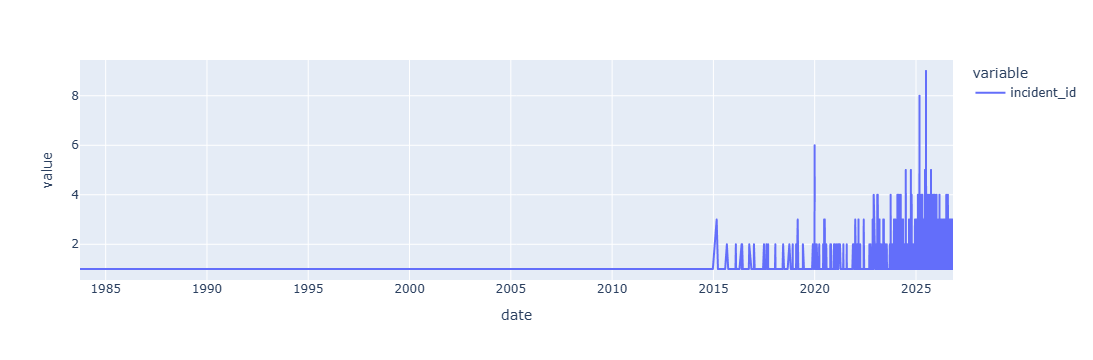

In [3]:
(
    incidents_df
    .reset_index()
    .groupby('date')['incident_id'].count()
    .pipe(px.line)
)

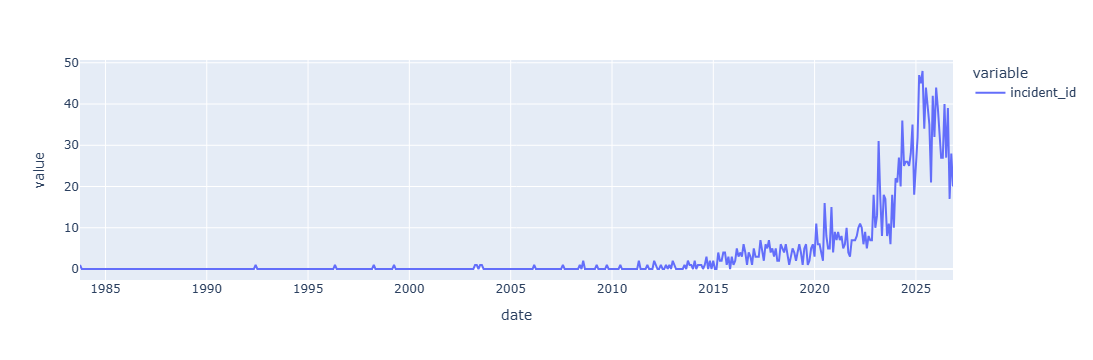

In [4]:
# monthly plot

(
    incidents_df
    .reset_index()
    .groupby('date')['incident_id'].count()
    .resample('1ME').sum()
    .pipe(px.line)
)

In [5]:
# 2. What were reported to be the 10 most common developers of these incidents? 

(
    incidents_df
    ['Alleged developer of AI system']
    .explode()
    .value_counts()
    .head(10)
)

Alleged developer of AI system
deepfake-technology-developers                      452
synthetic-audio-generation-technology-developers    241
openai                                              195
large-language-model-developers                     145
synthetic-media-generation-technology-developers    133
synthetic-image-generation-technology-developers    124
google                                               98
unknown                                              80
chatbot-developers                                   73
generative-ai-developers                             66
Name: count, dtype: int64

In [6]:
# Who were the 10 most commonly harmed people in these incidents?

(
    incidents_df
    ['Alleged harmed or nearly harmed parties']
    .explode()
    .value_counts()
    .head(10)
)

Alleged harmed or nearly harmed parties
epistemic-integrity                                449
general-public                                     355
privacy                                            196
educational-communities                            107
minors                                              99
democratic-integrity                                99
women-and-girls                                     97
students                                            94
women                                               80
national-security-and-intelligence-stakeholders     71
Name: count, dtype: int64

In [7]:
# 3. What words (with > 4 letters, lowercased, removing any "ly" at the end of the word) were most commonly used in the "description" of incidents?

(
    incidents_df
    ['description']
    .str.split()
    .explode()
    .str.lower()
    .str.removesuffix('ly')
    .loc[lambda s_: s_.str.len() > 4]
    .value_counts()
    .head(10)
)

description
reported        1697
alleged          788
ai-generated     431
purported        353
after            306
video            303
deepfake         273
which            255
using            243
false            224
Name: count, dtype: int64

In [8]:
# 4. Read the classifications information into a Pandas data frame. Keep the MIT classifications ("namespace") that have been published. Then turn the "attributes" column into individual rows with "short_name" and "value_json" columns. With that in hand, calculate the number of reports in each risk domain.

classifications_filename = 'data/bw-189-classifications.bson'

with open(classifications_filename, 'rb') as _f:
    classifications_df = (
        DataFrame(bson.decode_all(_f.read()))
        .loc[pd.col('namespace') == 'MIT']
        .loc[pd.col('publish') == True]
        .explode(column='attributes')
        .pipe(lambda df_: df_.assign(**pd.json_normalize(df_['attributes'])))
        .drop(columns=['namespace','attributes', 'publish'])
    )

classifications_df

,_id,notes,incidents,reports,created_at,short_name,value_json
1125,67c0dbed236f7a7229be9fa1,,[1],[],2025-02-27 21:41:01.428,Risk Domain,"""1. Discrimination and Toxicity"""
1125,67c0dbed236f7a7229be9fa1,,[1],[],2025-02-27 21:41:01.428,Risk Subdomain,"""1.2. Exposure to toxic content"""
1125,67c0dbed236f7a7229be9fa1,,[1],[],2025-02-27 21:41:01.428,Entity,"""AI"""
1125,67c0dbed236f7a7229be9fa1,,[1],[],2025-02-27 21:41:01.428,Intent,"""Unintentional"""
1125,67c0dbed236f7a7229be9fa1,,[1],[],2025-02-27 21:41:01.428,Timing,"""Post-deployment"""
...,...,...,...,...,...,...,...
2622,6a2c44d029f8d65171bf83d0,,[1509],[],2026-06-12 17:41:36.154,Risk Domain,"""4. Malicious Actors & Misuse"""
2622,6a2c44d029f8d65171bf83d0,,[1509],[],2026-06-12 17:41:36.154,Risk Subdomain,"""4.3. Fraud, scams, and targeted manipulation"""
2622,6a2c44d029f8d65171bf83d0,,[1509],[],2026-06-12 17:41:36.154,Entity,"""AI"""
2622,6a2c44d029f8d65171bf83d0,,[1509],[],2026-06-12 17:41:36.154,Intent,"""Unintentional"""


In [9]:
(
    classifications_df
    .loc[pd.col('short_name') == 'Risk Domain']
    ['value_json']
    .value_counts()    
)

value_json
"4. Malicious Actors & Misuse"                      566
"7. AI system safety, failures, and limitations"    314
"1. Discrimination and Toxicity"                    244
"3. Misinformation"                                 196
"2. Privacy & Security"                             112
"5. Human-Computer Interaction"                      42
"6. Socioeconomic & Environmental Harms"             24
Name: count, dtype: int64

In [10]:
# 5. For each year since 2015, what percentage of AI incidents fell into each MIT risk domain? Did the mix change after ChatGPT was released in late 2022?

import json

(
    incidents_df
    .join(
        classifications_df
        .assign(incident_id=pd.col('incidents').str[0])
        .pivot(index='incident_id', columns='short_name', values='value_json')
        .map(json.loads, na_action='ignore'),
        how='left')
    .set_index('date')
    .sort_index()
    .loc['2015':, 'Risk Domain']
    .value_counts(normalize=True)
    .round(2)
)

Risk Domain
4. Malicious Actors & Misuse                      0.39
7. AI system safety, failures, and limitations    0.20
1. Discrimination and Toxicity                    0.16
3. Misinformation                                 0.13
2. Privacy & Security                             0.07
5. Human-Computer Interaction                     0.03
6. Socioeconomic & Environmental Harms            0.01
Name: proportion, dtype: float64

In [11]:
(
    incidents_df
    .join(
        classifications_df
        .assign(incident_id=pd.col('incidents').str[0])
        .pivot(index='incident_id', columns='short_name', values='value_json')
        .map(json.loads, na_action='ignore'),
        how='left')
    .set_index('date')
    .sort_index()
    .loc['2020':, 'Risk Domain']
    .value_counts(normalize=True)
    .round(2)
)

Risk Domain
4. Malicious Actors & Misuse                      0.44
7. AI system safety, failures, and limitations    0.17
3. Misinformation                                 0.15
1. Discrimination and Toxicity                    0.13
2. Privacy & Security                             0.07
5. Human-Computer Interaction                     0.03
6. Socioeconomic & Environmental Harms            0.01
Name: proportion, dtype: float64